# Violent Crime Trends

How does the unweighted mean state violent-crime rate change by year?

Data: [AER/Guns](https://vincentarelbundock.github.io/Rdatasets/doc/AER/Guns.html)

This notebook performs a descriptive analysis on a real historical dataset. Source limitations: Equal-state averages are not national population-weighted rates; no gun-law causal effect is estimated.

In [1]:
from pathlib import Path
from analysis import run
result = run(Path.cwd())
result["manifest"]

Out[0]: 
{'project': 'Violent Crime Trends',
 'executed_utc': '2026-11-21T10:14:15.920233+00:00',
 'source': 'https://vincentarelbundock.github.io/Rdatasets/csv/AER/Guns.csv',
 'documentation': 'https://vincentarelbundock.github.io/Rdatasets/doc/AER/Guns.html',
 'sha256': '177921ab3faa86cab3588e6c996ef10c39d6b4497555cc26c5a6ba223ba66cf4',
 'raw_rows': 1173,
 'analysis_rows': 1173,
 'excluded_rows': 0,
 'exact_duplicate_rows': 0,
 'duplicates_policy': 'Retained; duplicate values do not necessarily mean duplicate entities.',
 'python': '3.12.14',
 'pandas': '2.2.3',
 'numpy': '2.3.5',
 'matplotlib': '3.10.8'}


## Data quality
Missing required variables are excluded, not silently imputed. Repeated rows are preserved; review the source observation grain.

In [2]:
import pandas as pd
from IPython.display import display, Image
display(pd.read_csv("outputs/quality_audit.csv"))

,column,dtype,missing,missing_pct,distinct
0,rownames,int64,0,0.0,1173
1,year,int64,0,0.0,23
2,violent,float64,0,0.0,1101
3,murder,float64,0,0.0,184
4,robbery,float64,0,0.0,947
5,prisoners,int64,0,0.0,436
6,afam,float64,0,0.0,1173
7,cauc,float64,0,0.0,1173
8,male,float64,0,0.0,1173
9,population,float64,0,0.0,1173


## SQL and analysis
Complete-case descriptive comparison of violent by year; show group counts, mean, minimum and maximum.

In [3]:
print(Path("analysis.sql").read_text())
display(result["table"].head(30))
print(result["finding"])

SELECT "year" AS segment, COUNT(*) AS rows_used, AVG("violent") AS metric, MIN("violent") AS minimum, MAX("violent") AS maximum FROM observations GROUP BY "year" ORDER BY "year";

The first recorded mean is 392.825; the last is 458.490. The recorded period, rather than today, defines this comparison.


,segment,rows_used,metric,minimum,maximum
0,1977,51,392.825490,67.1,1426.5
1,1978,51,412.021569,67.0,1411.7
2,1979,51,455.041176,61.3,1608.7
3,1980,51,485.219608,54.0,2010.6
4,1981,51,489.282353,67.5,2274.8
5,1982,51,470.364706,61.8,2123.1
6,1983,51,439.580392,53.7,1915.4
7,1984,51,438.660784,53.6,1721.5
8,1985,51,450.484314,47.0,1624.8
9,1986,51,479.011765,51.3,1505.3


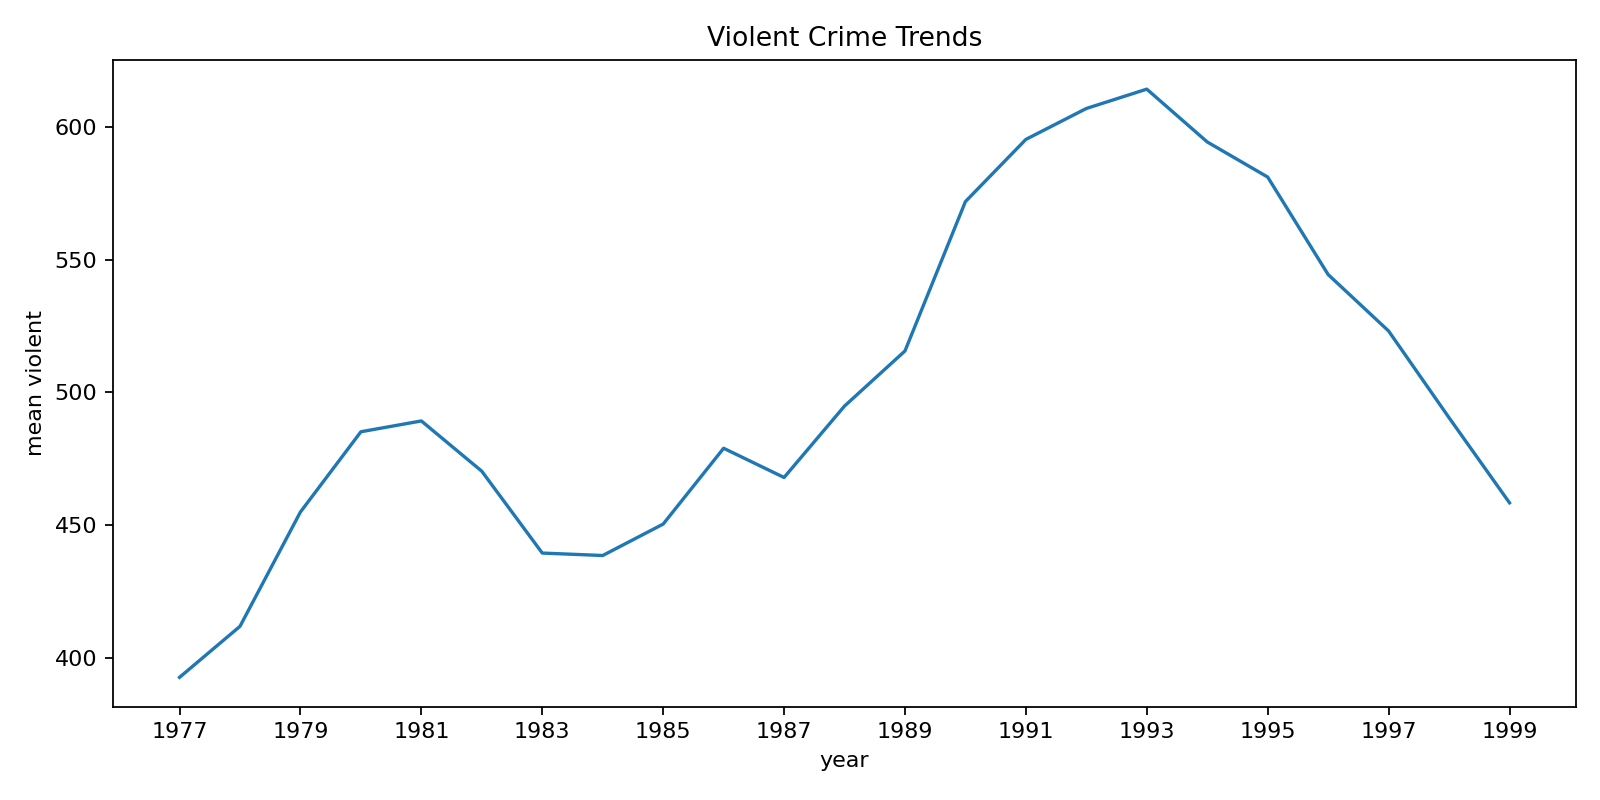

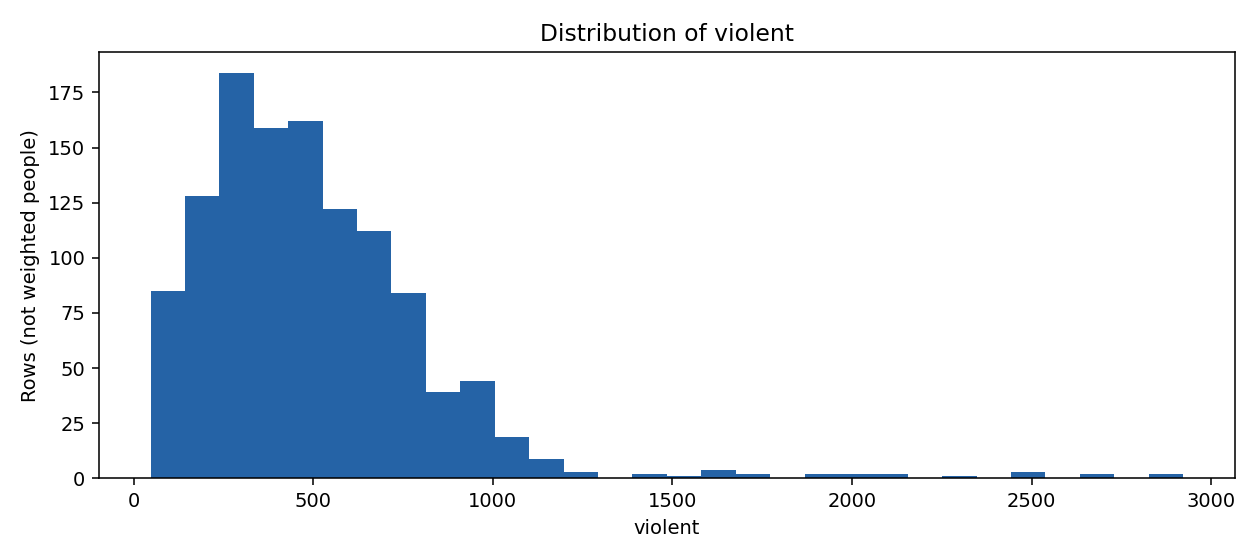

In [4]:
display(Image(filename="outputs/main_chart.png"))
display(Image(filename="outputs/distribution.png"))

## Interpretation
Equal-state averages are not national population-weighted rates; no gun-law causal effect is estimated.

**Next action:** Use matching population weights and policy identification before evaluating laws.

Read outputs/REPORT.md for executed findings. This project does not establish causation or a production decision rule.